POSITIVE CORRELATION
X: thermal_runaway_risk_index | Y: heat_generation_W
pandas  .corr()      : 0.928916
numpy   .corrcoef()  : 0.928916
scipy   .pearsonr()  : 0.928916 | p-value: 0.0

NEGATIVE CORRELATION
X: safety_margin_index | Y: heat_generation_W
pandas  .corr()      : -0.928765
numpy   .corrcoef()  : -0.928765
scipy   .pearsonr()  : -0.928765 | p-value: 0.0

NO CORRELATION
X: voltage_V | Y: heat_generation_W
pandas  .corr()      : 0.000477
numpy   .corrcoef()  : 0.000477
scipy   .pearsonr()  : 0.000477 | p-value: 0.9730842116438987

CORRELATION MATRIX
                            cycle_number  calendar_age_days  \
cycle_number                       1.000              1.000   
calendar_age_days                  1.000              1.000   
state_of_health_%                 -0.890             -0.890   
capacity_fade_%                    0.890              0.890   
resistance_growth_%                0.327              0.327   
internal_resistance_mOhm           0.327              0.3

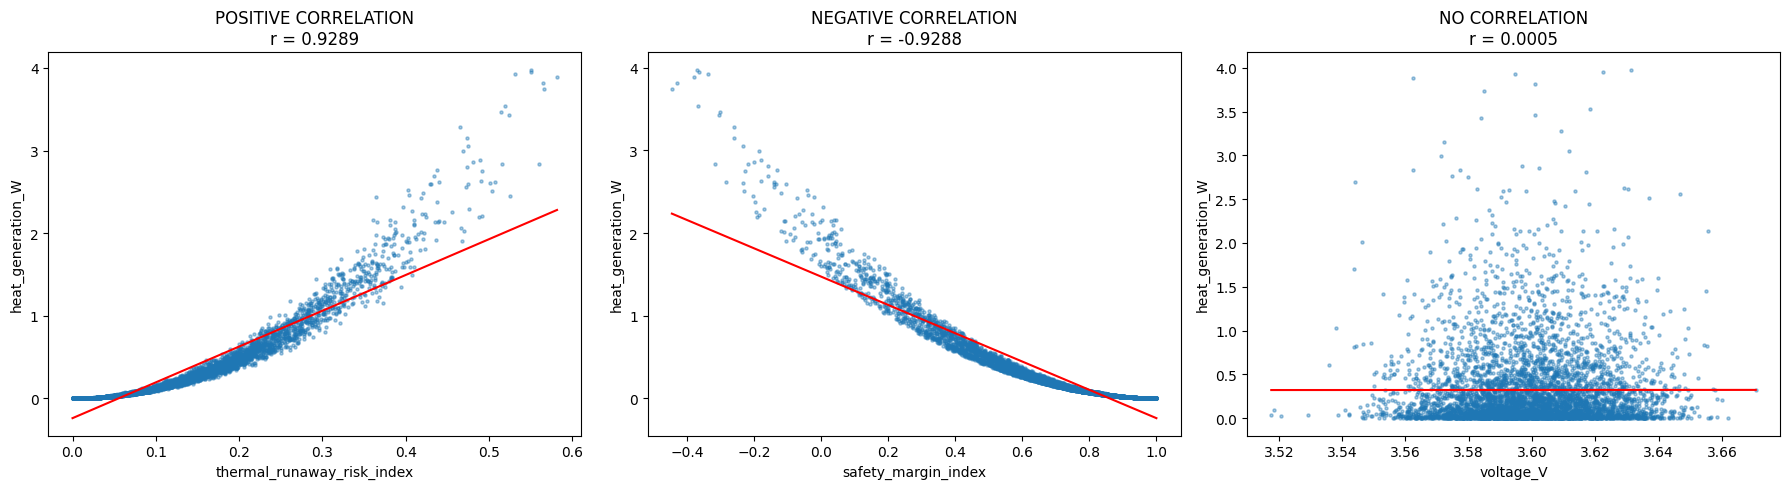

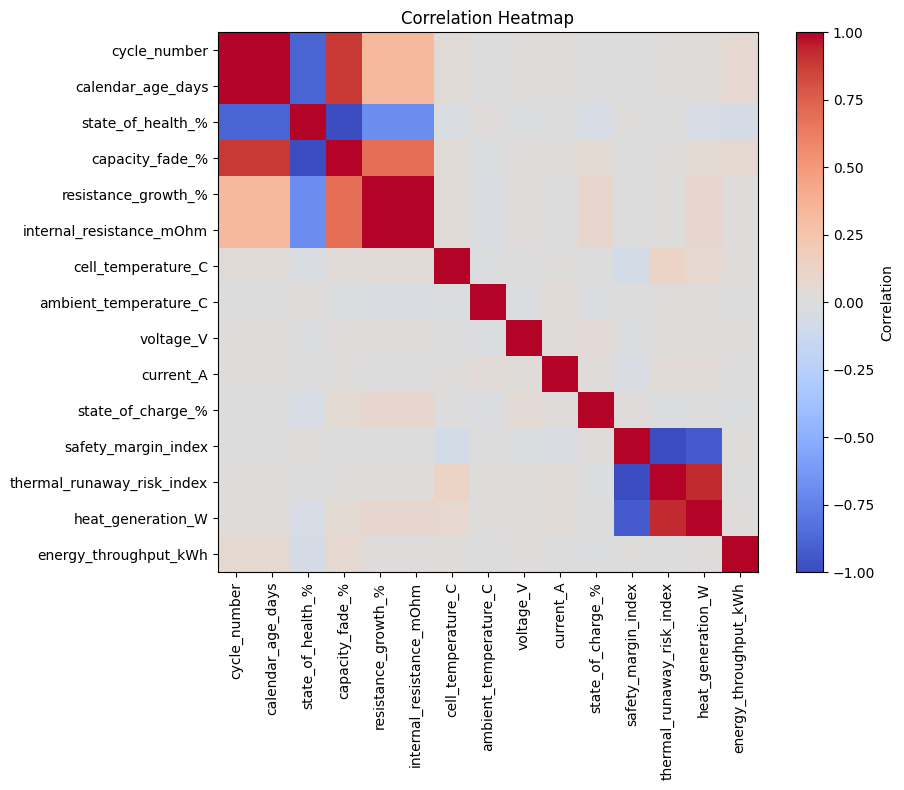

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv(r"C:\Users\Chetan\Downloads\archive\synthetic_ev_battery_5year_50cols_multimfg_3M.csv")
sample = df.sample(n=5000, random_state=42)

candidates = [
    "cycle_number", "calendar_age_days", "state_of_health_%", "capacity_fade_%",
    "resistance_growth_%", "internal_resistance_mOhm", "cell_temperature_C",
    "ambient_temperature_C", "voltage_V", "current_A", "state_of_charge_%",
    "safety_margin_index", "thermal_runaway_risk_index", "heat_generation_W",
    "energy_throughput_kWh"
]
candidates = [c for c in candidates if c in sample.columns and sample[c].std() > 0]

corr_matrix = sample[candidates].corr()
mask = np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)
pairs = corr_matrix.where(mask).stack()

pairs_not_trivial = pairs[pairs.abs() < 0.99]   # skip near-identical columns

pos_pair = pairs_not_trivial.idxmax()           # strongest positive
neg_pair = pairs_not_trivial.idxmin()           # strongest negative
zero_pair = pairs.abs().idxmin()                # closest to zero

cases = [
    ("POSITIVE CORRELATION", pos_pair),
    ("NEGATIVE CORRELATION", neg_pair),
    ("NO CORRELATION", zero_pair),
]

results = {}
for title, (col_x, col_y) in cases:
    x = sample[col_x]
    y = sample[col_y]

    r_pandas = x.corr(y)                         # pandas
    r_numpy = np.corrcoef(x, y)[0, 1]            # numpy
    r_scipy, p_value = stats.pearsonr(x, y)      # scipy (also gives p-value)

    results[title] = (col_x, col_y, x, y, r_pandas)

    print(title)
    print("X:", col_x, "| Y:", col_y)
    print("pandas  .corr()      :", round(r_pandas, 6))
    print("numpy   .corrcoef()  :", round(r_numpy, 6))
    print("scipy   .pearsonr()  :", round(r_scipy, 6), "| p-value:", p_value)
    print()

print("CORRELATION MATRIX")
print(corr_matrix.round(3))


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (title, (col_x, col_y, x, y, r)) in zip(axes, results.items()):
    ax.scatter(x, y, s=5, alpha=0.4)

    slope, intercept = np.polyfit(x, y, 1)       # best fit line
    xs = np.array([x.min(), x.max()])
    ax.plot(xs, slope * xs + intercept, color="red")

    ax.set_title(f"{title}\nr = {r:.4f}")
    ax.set_xlabel(col_x)
    ax.set_ylabel(col_y)

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(candidates)), candidates, rotation=90)
plt.yticks(range(len(candidates)), candidates)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()
